# Solutions · 17 · Multivariable basics

Worked solutions to the exercises of [notebook 17](../notebooks/17_multivariable_basics.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, mimo, frequency as fr, response as rs, design as dg, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Design the two PI loops of the column by SIMC with lambda = 5, 10 and 20 min, with and without the static decoupler, and tabulate the interaction (peak of the other output for a setpoint step) and the settling time. Does decoupling ever hurt?

In [2]:
col = models.distillation_2x2()
G = col["system"]; G0 = G.dcgain(); D = mimo.static_decoupler(G0)
def closed_loop_2x2(plant, controllers, decoupler=None):
    C1, C2 = controllers
    s1, s2 = C1.to_ss(), C2.to_ss()
    Cs = sy.ss(np.block([[s1.A, np.zeros((s1.n, s2.n))], [np.zeros((s2.n, s1.n)), s2.A]]), np.block([[s1.B, np.zeros((s1.n, 1))], [np.zeros((s2.n, 1)), s2.B]]),
               np.block([[s1.C, np.zeros((1, s2.n))], [np.zeros((1, s1.n)), s2.C]]), np.block([[s1.D, np.zeros((1, 1))], [np.zeros((1, 1)), s2.D]]))
    if decoupler is not None:
        Cs = sy.ss(Cs.A, Cs.B, decoupler @ Cs.C, decoupler @ Cs.D)
    return sy.feedback(sy.series(Cs, plant))
rows = []
for lam in (5.0, 10.0, 20.0):
    C1 = dg.pid_standard(16.7 / (12.8 * lam), min(16.7, 4 * lam)); C2 = dg.pid_standard(-14.4 / (19.4 * lam), min(14.4, 4 * lam))
    C1d = dg.pid_standard(16.7 / lam, min(16.7, 4 * lam)); C2d = dg.pid_standard(14.4 / lam, min(14.4, 4 * lam))   # retuned for the decoupled plant G D (unit gains)
    for name, ctrls, dec in (("decentralised", (C1, C2), None), ("decoupled", (C1d, C2d), D)):
        T = closed_loop_2x2(G, ctrls, dec)
        t, y = rs.step(T, 150.0, input_index=0)
        info = rs.step_info(t, y[:, 0], final=1.0)
        rows.append((lam, name, bool(np.max(T.poles().real) < 0), info["settling_time"], np.max(np.abs(y[:, 1]))))
print(pd.DataFrame(rows, columns=["lambda (min)", "structure", "stable", "settling of y1 (min)", "peak |y2| (interaction)"]).to_string(index=False, float_format="%.3f"))

 lambda (min)     structure  stable  settling of y1 (min)  peak |y2| (interaction)
        5.000 decentralised    True                54.600                    0.288
        5.000     decoupled    True                33.300                    0.111
       10.000 decentralised    True               112.950                    0.267
       10.000     decoupled    True                56.400                    0.090
       20.000 decentralised    True                   NaN                    0.241
       20.000     decoupled    True                96.300                    0.068


Decoupling cuts the interaction to a third at every tuning and makes the loops faster for the same λ - once
the controllers are retuned for the decoupled plant, whose dc gains are +1 on both channels (with the raw
controllers, the steam loop's negative gain turns into positive feedback through the decoupler and the loop
is slowly unstable). Static decoupling never hurt here, but it can: a decoupler inverts the dc gain, and when
that matrix is ill-conditioned the decoupler amplifies model errors (the column's condition number of 7.5 is
benign; the original Wood-Berry column with its delays is less so).

## Exercise 2

For the quarter car (inputs: road and actuator force; outputs: body acceleration and suspension travel) compute the singular values from 0.1 to 100 rad/s and explain the two peaks. Which input direction is the hardest to attenuate?

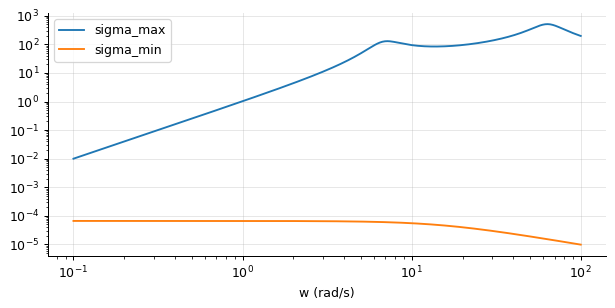

peaks of the largest singular value near 7.2 rad/s (body bounce) and 63.8 rad/s (wheel hop)
at wheel hop the most amplified input direction is [1. 0.] in [road, actuator force] - the road input dominates: an actuator alone cannot cancel wheel hop


In [3]:
qc = models.quarter_car()["system"]
w = np.logspace(-1, 2, 400)
sv = mimo.sigma(qc, w)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.loglog(w, sv[:, 0], label="sigma_max"); ax.loglog(w, sv[:, 1], label="sigma_min"); ax.legend(); ax.set_xlabel("w (rad/s)"); plt.show()
i1, i2 = np.argmax(sv[:, 0] * (w < 20)), np.argmax(sv[:, 0] * (w > 20))
print(f"peaks of the largest singular value near {w[i1]:.1f} rad/s (body bounce) and {w[i2]:.1f} rad/s (wheel hop)")
U, s, Vt = np.linalg.svd(fr.freqresp(qc, w[i2]))
print(f"at wheel hop the most amplified input direction is {np.round(np.abs(Vt[0]), 3)} in [road, actuator force] - the road input dominates: an actuator alone cannot cancel wheel hop")

The two peaks of the largest singular value are the suspension's two resonances; the right singular vector
at the wheel-hop peak points almost entirely along the road input, meaning the road excites that mode far
more than the actuator can act on it - the input direction that is hardest to attenuate. Singular values and
their vectors turn a 2 × 2 frequency response into a statement about which disturbances a controller can
fight.

## Exercise 3

**Implement it yourself:** write a dynamic decoupler D(s) = G(s)^-1 G_diag(s) for the 2 x 2 column (each entry a transfer function) and show that G D is diagonal; is D proper and stable?

In [4]:
col = models.distillation_2x2()
TM = mimo.transfer_matrix(col["system"])
from englincontrol import polynomials as pl
N = [[TM[i][j].num for j in range(2)] for i in range(2)]; Dn = [[TM[i][j].den for j in range(2)] for i in range(2)]
# det G = (N11 N22 D12 D21 - N12 N21 D11 D22) / (D11 D22 D12 D21); D = G^-1 G_diag = adj(G) G_diag / det
det_num = pl.sub(pl.mul(pl.mul(N[0][0], N[1][1]), pl.mul(Dn[0][1], Dn[1][0])), pl.mul(pl.mul(N[0][1], N[1][0]), pl.mul(Dn[0][0], Dn[1][1])))
D11 = sy.tf(pl.mul(pl.mul(N[1][1], N[0][0]), pl.mul(Dn[0][1], Dn[1][0])), det_num).cancel()        # G22 G11 / det
D12 = sy.tf(-pl.mul(pl.mul(N[0][1], N[1][1]), pl.mul(Dn[0][0], Dn[1][0])), det_num).cancel()       # -G12 G22 / det
D21 = sy.tf(-pl.mul(pl.mul(N[1][0], N[0][0]), pl.mul(Dn[1][1], Dn[0][1])), det_num).cancel()       # -G21 G11 / det
D22 = sy.tf(pl.mul(pl.mul(N[0][0], N[1][1]), pl.mul(Dn[0][1], Dn[1][0])), det_num).cancel()        # G11 G22 / det
w = 0.05
Gw = fr.freqresp(col["system"], w)
Dw = np.array([[fr.freqresp(D11, w), fr.freqresp(D12, w)], [fr.freqresp(D21, w), fr.freqresp(D22, w)]])
print("G D at w = 0.05 (should be diagonal):\n", np.round(Gw @ Dw, 6))
print("proper:", all(len(d.num) <= len(d.den) for d in (D11, D12, D21, D22)), "| stable:", all(np.all(d.poles().real < 0) for d in (D11, D12, D21, D22)), "| poles of D are the zeros of det G:", np.round(pl.roots(det_num), 4))

G D at w = 0.05 (should be diagonal):
 [[  7.541723-6.297338j   0.      -0.j      ]
 [  0.      -0.j       -12.776607+9.199157j]]
proper: True | stable: True | poles of D are the zeros of det G: [-0.1079 -0.0427]


The dynamic decoupler D = G⁻¹G_diag makes G D diagonal at every frequency, not just at dc; its poles are the
transmission zeros of G (the roots of det G), so it is stable only when the plant is minimum-phase, and it is
proper here because the entries share their relative degree. For plants with RHP transmission zeros or delays
an exact dynamic decoupler is unstable or non-causal, and one falls back to approximate or static decoupling.